Speed MAE: 0.5657220958622914
Speed R2: 0.9114741658011023
Acceleration MAE: 0.17286372942603956
Acceleration R2: 0.3344616917157811


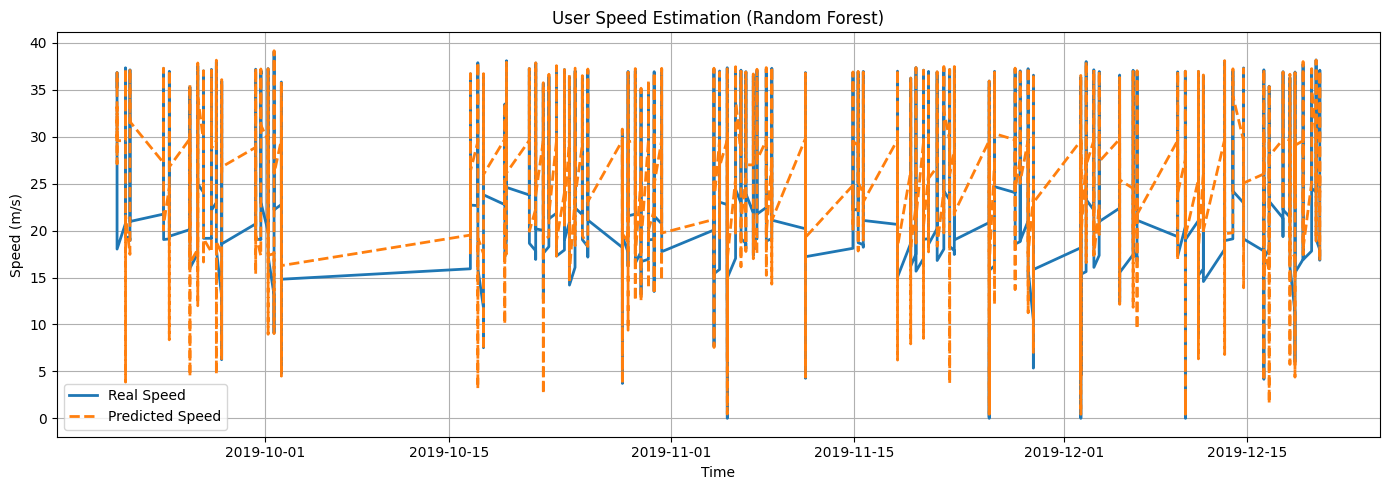

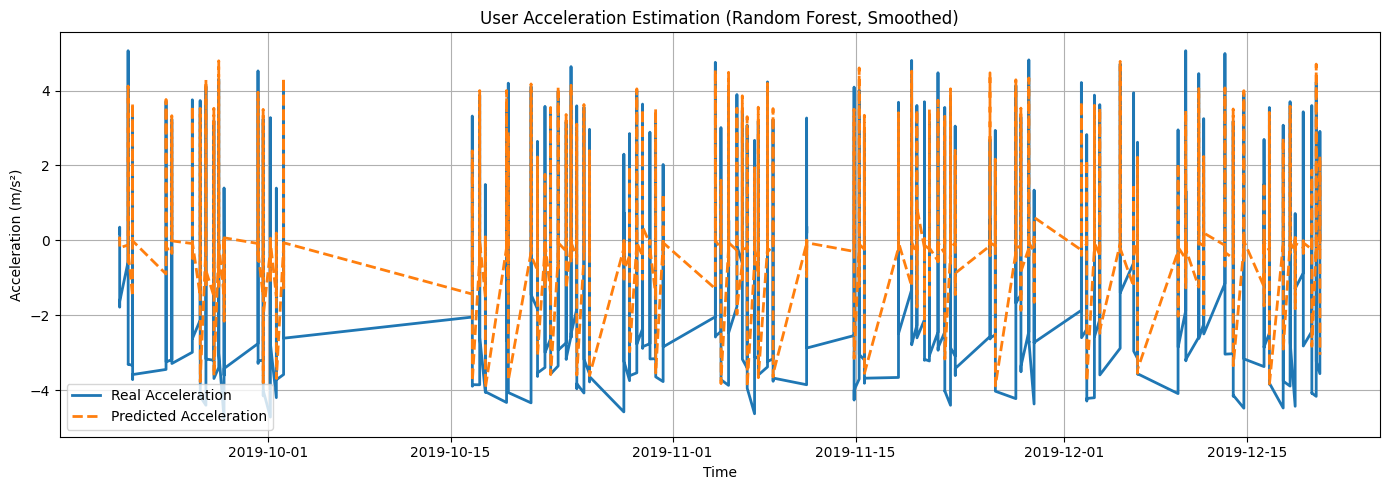

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, r2_score


df = pd.read_csv('SRFG-v1.csv')


df['time'] = pd.to_datetime(df['time'], errors='coerce')

df = df.sort_values('time').dropna(subset=['time']).reset_index(drop=True)


def haversine(lat1, lon1, lat2, lon2):

    R = 6371000

    phi1, phi2 = np.radians(lat1), np.radians(lat2)

    dphi = np.radians(lat2 - lat1)

    dlambda = np.radians(lon2 - lon1)

    a = np.sin(dphi / 2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2)**2

    return R * 2 * np.arcsin(np.sqrt(a))


df['distance'] = haversine(df['lat'].shift(1), df['long'].shift(1), df['lat'], df['long'])

df['dt'] = (df['time'] - df['time'].shift(1)).dt.total_seconds()

df = df.dropna(subset=['distance', 'dt'])

df = df[df['dt'] > 0]


df['speed_raw'] = df['distance'] / df['dt']

df = df[df['speed_raw'] < 40].reset_index(drop=True)

df['speed'] = df['speed_raw'].rolling(3, center=True).mean().fillna(df['speed_raw'])


df['acceleration'] = df['speed'].diff() / df['dt']

df['acceleration'] = df['acceleration'].rolling(3, center=True).mean().fillna(0)


for c in ['rsrp', 'rsrq', 'sinr']:

    df[f'{c}_avg'] = df[c].rolling(5, min_periods=1).mean()

    df[f'{c}_std'] = df[c].rolling(5, min_periods=1).std().fillna(0)


features = ['rsrp','rsrq','sinr','rsrp_avg','rsrp_std','rsrq_std','sinr_std','dlat','dlong']

df[features] = df[features].apply(pd.to_numeric, errors='coerce').fillna(0)


split = int(0.8 * len(df))

X_train, X_test = df[features].iloc[:split], df[features].iloc[split:]

y_speed_train, y_speed_test = df['speed'].iloc[:split], df['speed'].iloc[split:]

y_acc_train, y_acc_test = df['acceleration'].iloc[:split], df['acceleration'].iloc[split:]


speed_model = RandomForestRegressor(n_estimators=250, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1)

acc_model   = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=4, random_state=42, n_jobs=-1)


speed_model.fit(X_train, y_speed_train)

acc_model.fit(X_train, y_acc_train)


speed_pred = speed_model.predict(X_test)

acc_pred   = acc_model.predict(X_test)


print('Speed MAE:', mean_absolute_error(y_speed_test, speed_pred))

print('Speed R2:', r2_score(y_speed_test, speed_pred))

print('Acceleration MAE:', mean_absolute_error(y_acc_test, acc_pred))

print('Acceleration R2:', r2_score(y_acc_test, acc_pred))


t = df['time'].iloc[split:].reset_index(drop=True)


plt.figure(figsize=(14,5))

plt.plot(t, y_speed_test.values, label='Real Speed', linewidth=2)

plt.plot(t, speed_pred, '--', label='Predicted Speed', linewidth=2)

plt.xlabel('Time')

plt.ylabel('Speed (m/s)')

plt.title('User Speed Estimation (Random Forest)')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


plt.figure(figsize=(14,5))

plt.plot(t, y_acc_test.values, label='Real Acceleration', linewidth=2)

plt.plot(t, acc_pred, '--', label='Predicted Acceleration', linewidth=2)

plt.xlabel('Time')

plt.ylabel('Acceleration (m/s²)')

plt.title('User Acceleration Estimation (Random Forest, Smoothed)')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

Speed MAE: 0.5655434711818403
Speed R2: 0.9116579663903291
Acceleration MAE: 0.03903771103895635
Acceleration R2: 0.8561635556200229


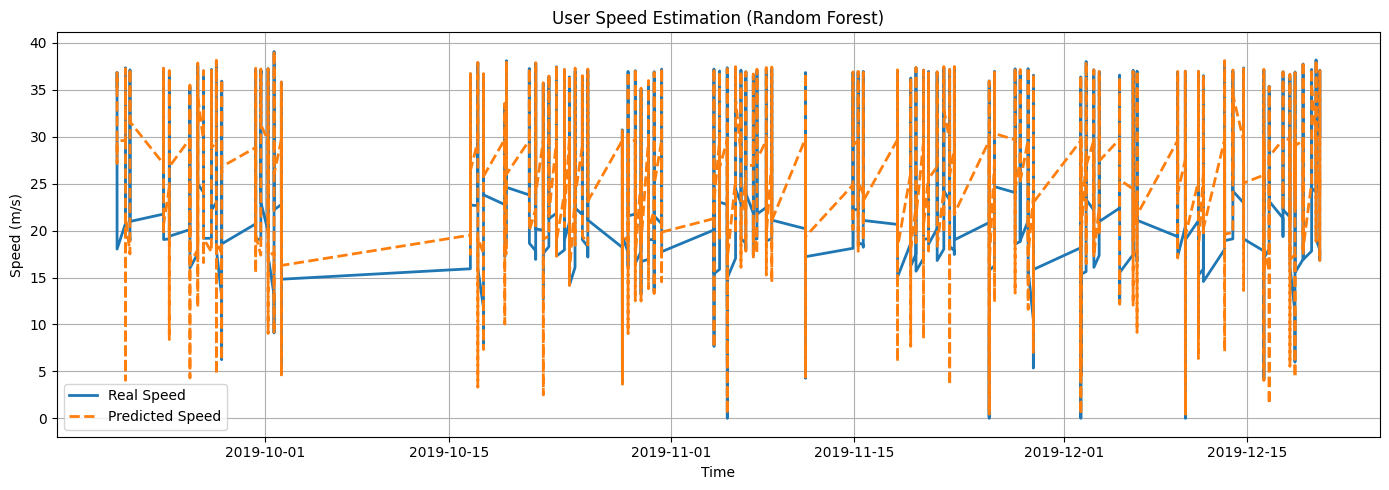

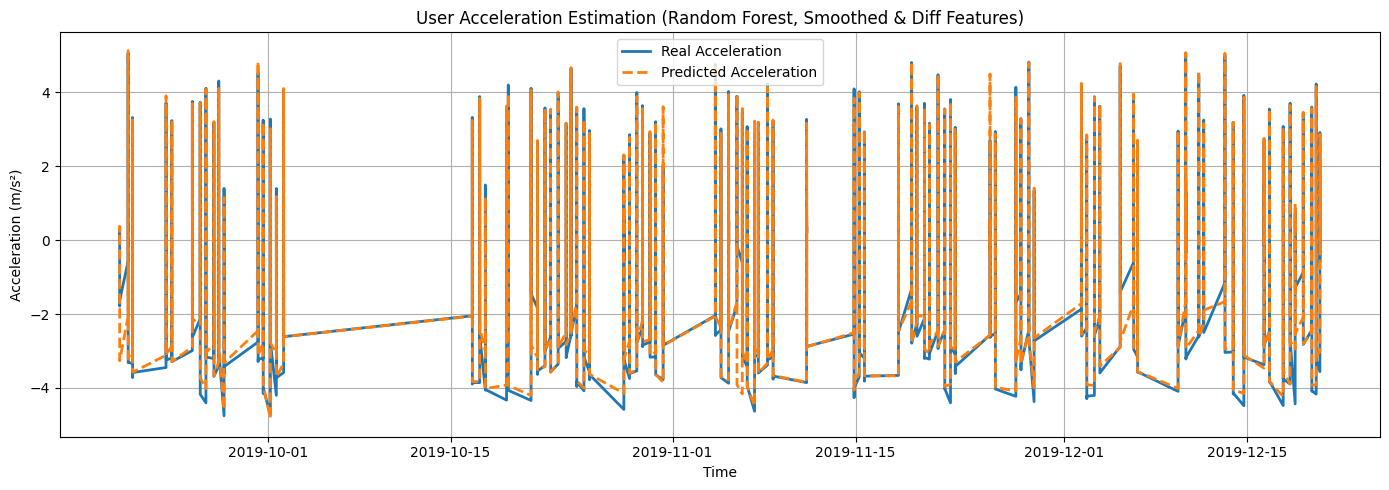

In [2]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, r2_score


df = pd.read_csv('SRFG-v1.csv')

df['time'] = pd.to_datetime(df['time'], errors='coerce')

df = df.sort_values('time').dropna(subset=['time']).reset_index(drop=True)


def haversine(lat1, lon1, lat2, lon2):

    R = 6371000

    phi1, phi2 = np.radians(lat1), np.radians(lat2)

    dphi = np.radians(lat2 - lat1)

    dlambda = np.radians(lon2 - lon1)

    a = np.sin(dphi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda/2)**2

    return R * 2 * np.arcsin(np.sqrt(a))


df['distance'] = haversine(df['lat'].shift(1), df['long'].shift(1),

                           df['lat'], df['long'])

df['dt'] = (df['time'] - df['time'].shift(1)).dt.total_seconds()

df = df.dropna(subset=['distance', 'dt'])

df = df[df['dt'] > 0]


df['speed_raw'] = df['distance'] / df['dt']

df = df[df['speed_raw'] < 40].reset_index(drop=True)

df['speed'] = df['speed_raw'].rolling(3, center=True).mean().fillna(df['speed_raw'])

df['acceleration'] = df['speed'].diff() / df['dt']

df['acceleration'] = df['acceleration'].fillna(0)

df['acceleration_smooth'] = df['acceleration'].rolling(3, center=True).mean().fillna(df['acceleration'])


for c in ['rsrp', 'rsrq', 'sinr']:

    df[f'{c}_avg'] = df[c].rolling(5, min_periods=1).mean()

    df[f'{c}_std'] = df[c].rolling(5, min_periods=1).std().fillna(0)

    df[f'{c}_diff'] = df[c].diff().fillna(0)


df['speed_diff1'] = df['speed'].diff().fillna(0)

df['speed_diff2'] = df['speed'].diff(2).fillna(0)


speed_features = ['rsrp','rsrq','sinr','rsrp_avg','rsrp_std','rsrq_std','sinr_std','dlat','dlong']

acc_features = speed_features + ['speed_diff1','speed_diff2','rsrp_diff','rsrq_diff','sinr_diff']


df[speed_features] = df[speed_features].apply(pd.to_numeric, errors='coerce').fillna(0)

df[acc_features] = df[acc_features].apply(pd.to_numeric, errors='coerce').fillna(0)


split = int(0.8 * len(df))

X_speed_train, X_speed_test = df[speed_features].iloc[:split], df[speed_features].iloc[split:]

y_speed_train, y_speed_test = df['speed'].iloc[:split], df['speed'].iloc[split:]


X_acc_train, X_acc_test = df[acc_features].iloc[:split], df[acc_features].iloc[split:]

y_acc_train, y_acc_test = df['acceleration_smooth'].iloc[:split], df['acceleration_smooth'].iloc[split:]


speed_model = RandomForestRegressor(

    n_estimators=300,

    max_depth=12,

    min_samples_leaf=3,

    random_state=42,

    n_jobs=-1

)


acc_model = RandomForestRegressor(

    n_estimators=250,

    max_depth=10,

    min_samples_leaf=3,

    random_state=42,

    n_jobs=-1

)


speed_model.fit(X_speed_train, y_speed_train)

acc_model.fit(X_acc_train, y_acc_train)


speed_pred = speed_model.predict(X_speed_test)

acc_pred = acc_model.predict(X_acc_test)


print("Speed MAE:", mean_absolute_error(y_speed_test, speed_pred))

print("Speed R2:", r2_score(y_speed_test, speed_pred))

print("Acceleration MAE:", mean_absolute_error(y_acc_test, acc_pred))

print("Acceleration R2:", r2_score(y_acc_test, acc_pred))


t = df['time'].iloc[split:].reset_index(drop=True)


plt.figure(figsize=(14,5))

plt.plot(t, y_speed_test.values, label='Real Speed', linewidth=2)

plt.plot(t, speed_pred, '--', label='Predicted Speed', linewidth=2)

plt.xlabel('Time')

plt.ylabel('Speed (m/s)')

plt.title('User Speed Estimation (Random Forest)')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


plt.figure(figsize=(14,5))

plt.plot(t, y_acc_test.values, label='Real Acceleration', linewidth=2)

plt.plot(t, acc_pred, '--', label='Predicted Acceleration', linewidth=2)

plt.xlabel('Time')

plt.ylabel('Acceleration (m/s²)')

plt.title('User Acceleration Estimation (Random Forest, Smoothed & Diff Features)')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

Speed MAE: 0.5944580340938732
Speed R2: 0.9165835781686633
Acceleration MAE: 0.038210353654607086
Acceleration R2: 0.9073158674892083


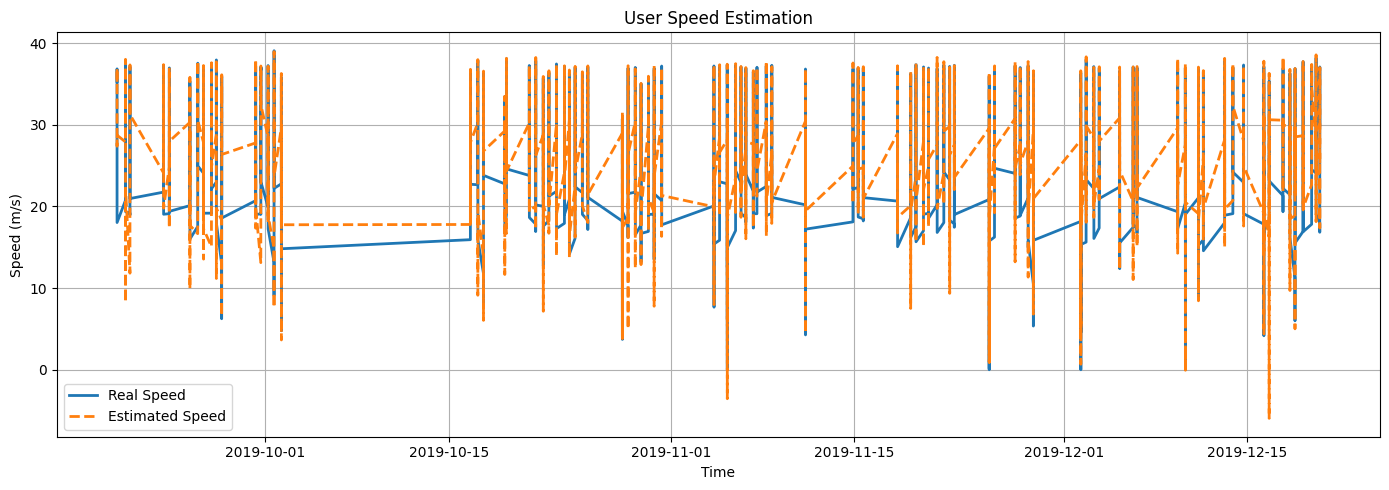

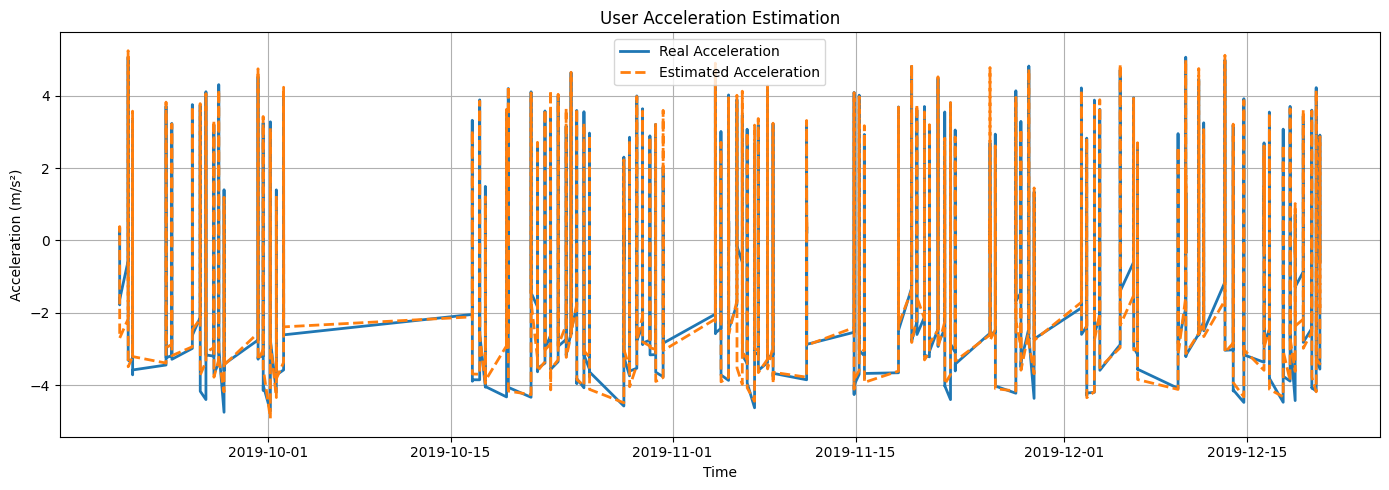

In [3]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, r2_score


df = pd.read_csv('SRFG-v1.csv')

df['time'] = pd.to_datetime(df['time'], errors='coerce')

df = df.sort_values('time').dropna(subset=['time']).reset_index(drop=True)


def haversine(lat1, lon1, lat2, lon2):

    R = 6371000

    phi1, phi2 = np.radians(lat1), np.radians(lat2)

    dphi = np.radians(lat2 - lat1)

    dlambda = np.radians(lon2 - lon1)

    a = np.sin(dphi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda/2)**2

    return R * 2 * np.arcsin(np.sqrt(a))


df['distance'] = haversine(df['lat'].shift(1), df['long'].shift(1),

                           df['lat'], df['long'])

df['dt'] = (df['time'] - df['time'].shift(1)).dt.total_seconds()

df = df.dropna(subset=['distance', 'dt'])

df = df[df['dt'] > 0]


df['speed_raw'] = df['distance'] / df['dt']

df = df[df['speed_raw'] < 40].reset_index(drop=True)

df['speed'] = df['speed_raw'].rolling(3, center=True).mean().fillna(df['speed_raw'])

df['acceleration'] = df['speed'].diff() / df['dt']

df['acceleration'] = df['acceleration'].fillna(0)

df['acceleration_smooth'] = df['acceleration'].rolling(3, center=True).mean().fillna(df['acceleration'])


for c in ['rsrp', 'rsrq', 'sinr']:

    df[f'{c}_avg'] = df[c].rolling(5, min_periods=1).mean()

    df[f'{c}_std'] = df[c].rolling(5, min_periods=1).std().fillna(0)

    df[f'{c}_diff'] = df[c].diff().fillna(0)


speed_features = [

    'rsrp', 'rsrq', 'sinr',

    'rsrp_avg', 'rsrp_std',

    'rsrq_std', 'sinr_std',

    'dlat', 'dlong'

]


df['speed_diff1'] = df['speed'].diff().fillna(0)

df['speed_diff2'] = df['speed'].diff(2).fillna(0)


acc_features = speed_features + [

    'speed_diff1', 'speed_diff2',

    'rsrp_diff', 'rsrq_diff', 'sinr_diff'

]


df[speed_features] = df[speed_features].apply(pd.to_numeric, errors='coerce').fillna(0)

df[acc_features] = df[acc_features].apply(pd.to_numeric, errors='coerce').fillna(0)


split = int(0.8 * len(df))

X_speed_train, X_speed_test = df[speed_features].iloc[:split], df[speed_features].iloc[split:]

y_speed_train, y_speed_test = df['speed'].iloc[:split], df['speed'].iloc[split:]


X_acc_train, X_acc_test = df[acc_features].iloc[:split], df[acc_features].iloc[split:]

y_acc_train, y_acc_test = df['acceleration_smooth'].iloc[:split], df['acceleration_smooth'].iloc[split:]


speed_model = GradientBoostingRegressor(

    n_estimators=400,

    learning_rate=0.08,

    max_depth=5,

    subsample=0.8,

    random_state=42

)


acc_model = GradientBoostingRegressor(

    n_estimators=400,

    learning_rate=0.1,

    max_depth=5,

    subsample=0.8,

    random_state=42

)


speed_model.fit(X_speed_train, y_speed_train)

acc_model.fit(X_acc_train, y_acc_train)


speed_pred = speed_model.predict(X_speed_test)

acc_pred = acc_model.predict(X_acc_test)


print("Speed MAE:", mean_absolute_error(y_speed_test, speed_pred))

print("Speed R2:", r2_score(y_speed_test, speed_pred))

print("Acceleration MAE:", mean_absolute_error(y_acc_test, acc_pred))

print("Acceleration R2:", r2_score(y_acc_test, acc_pred))


t = df['time'].iloc[split:].reset_index(drop=True)


plt.figure(figsize=(14,5))

plt.plot(t, y_speed_test.values, label='Real Speed', linewidth=2)

plt.plot(t, speed_pred, '--', label='Estimated Speed', linewidth=2)

plt.xlabel('Time')

plt.ylabel('Speed (m/s)')

plt.title('User Speed Estimation')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


plt.figure(figsize=(14,5))

plt.plot(t, y_acc_test.values, label='Real Acceleration', linewidth=2)

plt.plot(t, acc_pred, '--', label='Estimated Acceleration', linewidth=2)

plt.xlabel('Time')

plt.ylabel('Acceleration (m/s²)')

plt.title('User Acceleration Estimation')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()